# 1. The synthetic dataset

These notebooks show how the **Ukraine HIV recency hotspot pipeline** works, using
only a **fully synthetic** dataset. They run in your browser (JupyterLite): nothing
is installed on your computer and no data leaves the page.

**What the data are.** The pipeline uses results of recent-infection testing among
people newly diagnosed with HIV. Each record is one test at one testing site, marked
*recent* or *long-term*. The synthetic file has exactly that structure, but **no
record and no location is real**: sites are random points inside an oblast and
case counts are random draws. In this dataset about one to two per cent of tests are
recent.

**What the notebooks cover.**

1. this notebook: the synthetic data;
2. how the detector turns test counts into labels;
3. maps of the results;
4. does the answer depend on the grid? (eight different grids);
5. running the Bayesian model live in the browser.

The precomputed results in `data/` were produced by running the unchanged pipeline
on this synthetic dataset; see `jupyterlite/build_content.py` in the repository.

In [1]:
# In the browser (JupyterLite) install the packages this notebook needs.
# On a normal Python kernel this cell does nothing.
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["pandas", "geopandas", "shapely", "pyproj", "matplotlib", "scipy"])

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from hotspots_lite import build_info, load_cases, load_sites, load_oblasts

info = build_info()
cases = load_cases()
sites = load_sites()
oblasts = load_oblasts()

recent = cases["type"].eq("recent")
pd.Series({
    "tests": len(cases),
    "testing sites": len(sites),
    "recent share (all years)": round(recent.mean(), 4),
    "first test": cases["test_date"].min().date(),
    "last test": cases["test_date"].max().date(),
    "analysis window used in notebooks 2-5": f"{info['window_start']} to {info['window_end']}",
}, dtype=object)

tests                                                       18185
testing sites                                                  94
recent share (all years)                                   0.0236
first test                                             2020-12-12
last test                                              2026-05-31
analysis window used in notebooks 2-5    2025-12-01 to 2026-05-31
dtype: object

## Two windows: current and baseline

The detector compares an **analysis window** (here six months) with a **baseline
window** just before it. The baseline length follows from the window length: one to
six months of analysis get a twelve-month baseline. The plot shows the monthly recent
share with both windows shaded. Note how noisy a monthly share is when only one or two
per cent of tests are recent; this sparsity shapes every design choice that follows.

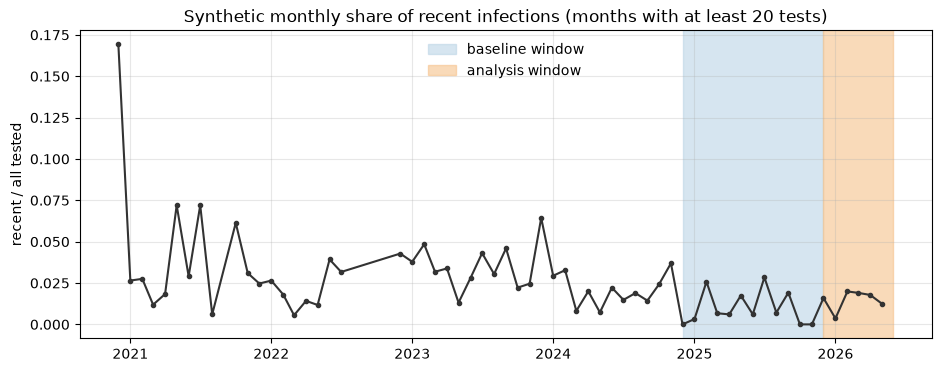

baseline  2024-12-01 to 2025-11-30:  3543 tests,  35 recent
analysis  2025-12-01 to 2026-05-31:  1755 tests,  26 recent


In [3]:
start, end = pd.Timestamp(info["window_start"]), pd.Timestamp(info["window_end"])
b_start, b_end = start - pd.DateOffset(months=12), start - pd.Timedelta(days=1)

monthly = (cases.assign(recent=recent, month=cases["test_date"].dt.to_period("M"))
           .groupby("month")["recent"].agg(["sum", "count"]))
monthly["share"] = monthly["sum"] / monthly["count"]
monthly = monthly[monthly["count"] >= 20]   # drop months with very few tests

fig, ax = plt.subplots(figsize=(11, 4))
ax.axvspan(b_start, b_end, color="#bcd4e6", alpha=0.6, label="baseline window")
ax.axvspan(start, end, color="#f6c28b", alpha=0.6, label="analysis window")
ax.plot(monthly.index.to_timestamp(), monthly["share"], marker="o", ms=3, color="#333333")
ax.set_ylabel("recent / all tested")
ax.set_title("Synthetic monthly share of recent infections (months with at least 20 tests)")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.show()

for name, (a, b) in {"baseline": (b_start, b_end), "analysis": (start, end)}.items():
    w = cases[(cases.test_date >= a) & (cases.test_date <= b)]
    print(f"{name:9} {a.date()} to {b.date()}: {len(w):5} tests, {w.type.eq('recent').sum():3} recent")

## Where the sites are

Each synthetic site is a random point inside an oblast; none of these points is a
clinic location.

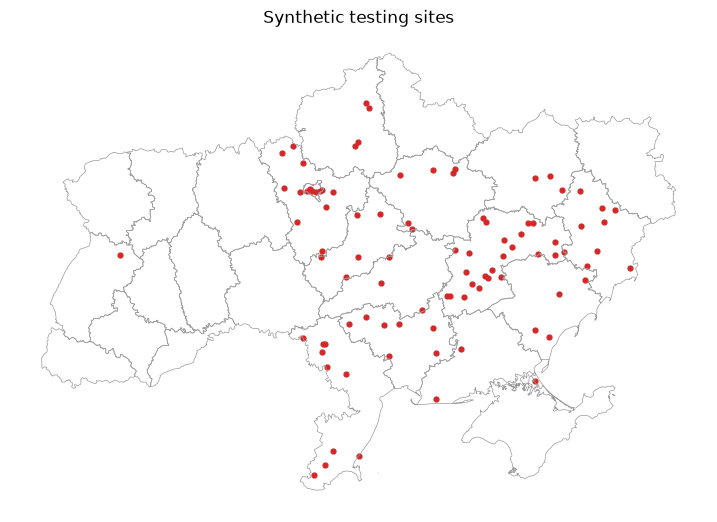

In [4]:
ax = oblasts.to_crs("EPSG:3035").boundary.plot(figsize=(9, 6.5), color="0.6", linewidth=0.5)
sites.to_crs("EPSG:3035").plot(ax=ax, color="#d62728", markersize=12)
ax.set_title("Synthetic testing sites")
ax.set_axis_off()
plt.show()